# **House Price Prediction – Baseline Regression Models**
- **Author:** Abdallah Idris Benseghir
- **Year:** 2026
- **Month:** November
- **Project:** House Price Prediction

#### **Dataset**: [House Prices – Advanced Regression Techniques (Kaggle)](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)

#### **Notebook Description**

**File:** `04_Baseline_Regression_Models.ipynb`

This notebook focuses on developing and evaluating baseline regression models to establish initial performance benchmarks for house price prediction.

Four regression algorithms are trained and compared to identify the most promising models for subsequent optimization.

##### **Main Operations**
- Import the required libraries, regression algorithms and evaluation metrics.
- Load and inspect the cleaned training and testing datasets.
- Separate independent features (X) from the target variable (`SalePrice`).
- Exclude unnecessary identifier columns (`Id`).
- Define four baseline regression models:
  - Linear Regression
  - Decision Tree Regressor
  - Random Forest Regressor
  - Support Vector Regression (SVR)
- Train each model using the training dataset.
- Generate house price predictions using the testing dataset.
- Evaluate model performance using MAE, MSE, RMSE and R².
- Compare model performance using a results table.
- Visualize R² scores and prediction errors.
- Identify the two best-performing baseline models based on R².

##### **Output**

The notebook produces:
- A model performance comparison table.
- R² score comparison visualization.
- MAE and RMSE comparison visualization.
- Actual vs Predicted scatterplots.
- Identification of the top two baseline regression models.

**Note:** The results establish baseline performance benchmarks and help determine which models should be considered for further hyperparameter tuning and optimization.

##### **Section 1 – Library Imports**

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

##### **Section 2 – Dataset Loading**

In [2]:
# Define dataset paths
train = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\clean_train.csv"
test = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\clean_test.csv"

# Load datasets
train_df = pd.read_csv(train)
test_df = pd.read_csv(test)

# Display training dataset dimensions
print("Training Dataset Shape:", train_df.shape)

# Display first five rows
display(train_df.head())



# Display testing dataset dimensions
print("\nTesting Dataset Shape:", test_df.shape)

# Statistical summary
display(test_df.describe())

Training Dataset Shape: (1103, 228)


,Id,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,255,20,70.0,8400,1,4,1,5,6,1957,...,0,0,0,1,0,0,0,0,1,0
1,1067,60,59.0,7837,1,3,1,6,7,1993,...,0,0,0,1,0,0,0,0,1,0
2,800,50,60.0,7200,1,4,1,5,7,1937,...,0,0,0,1,0,0,0,0,1,0
3,381,50,50.0,5000,1,4,1,5,6,1924,...,0,0,0,1,0,0,0,0,1,0
4,304,20,70.0,9800,1,4,1,5,7,1972,...,0,0,0,1,1,0,0,0,0,0



Testing Dataset Shape: (275, 228)


,Id,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
count,275.000000,275.000000,275.000000,275.000000,275.000000,275.000000,275.000000,275.000000,275.000000,275.000000,...,275.0,275.000000,275.0,275.000000,275.000000,275.0,275.000000,275.000000,275.000000,275.000000
mean,731.552727,55.636364,69.560000,9972.185455,0.992727,3.632727,1.076364,6.109091,5.549091,1973.818182,...,0.0,0.090909,0.0,0.872727,0.076364,0.0,0.018182,0.007273,0.800000,0.098182
std,405.652705,39.423938,19.529106,5957.465526,0.085125,0.553375,0.316207,1.409984,1.094257,27.871244,...,0.0,0.288004,0.0,0.333886,0.266063,0.0,0.133852,0.085125,0.400729,0.298103
min,16.000000,20.000000,21.000000,1680.000000,0.000000,1.000000,1.000000,2.000000,2.000000,1880.000000,...,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
25%,373.500000,20.000000,60.000000,7500.000000,1.000000,3.000000,1.000000,5.000000,5.000000,1955.500000,...,0.0,0.000000,0.0,1.000000,0.000000,0.0,0.000000,0.000000,1.000000,0.000000
50%,734.000000,50.000000,70.000000,9084.000000,1.000000,4.000000,1.000000,6.000000,5.000000,1976.000000,...,0.0,0.000000,0.0,1.000000,0.000000,0.0,0.000000,0.000000,1.000000,0.000000
75%,1070.500000,70.000000,78.000000,11355.500000,1.000000,4.000000,1.000000,7.000000,6.000000,2000.000000,...,0.0,0.000000,0.0,1.000000,0.000000,0.0,0.000000,0.000000,1.000000,0.000000
max,1448.000000,190.000000,174.000000,70761.000000,1.000000,4.000000,3.000000,10.000000,9.000000,2009.000000,...,0.0,1.000000,0.0,1.000000,1.000000,0.0,1.000000,1.000000,1.000000,1.000000


##### **Section 3 – Feature and Target Separation**

In [3]:
# Separate independent features (X) and dependent target (y)

# Training dataset
X_train = train_df.drop(columns=["SalePrice", "Id"], errors="ignore")
y_train = train_df["SalePrice"]

# Testing dataset
X_test = test_df.drop(columns=["SalePrice", "Id"], errors="ignore")
y_test = test_df["SalePrice"]

# Display shapes
print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)

print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (1103, 226)
y_train Shape: (1103,)
X_test Shape: (275, 226)
y_test Shape: (275,)


##### **Section 4 – Baseline Regression Model Definition**

In [4]:
# Define regression models
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),

    "Support Vector Regression": SVR(kernel="rbf")
}

##### **Section 5 – Model Training and Evaluation**

In [5]:
# Store model evaluation results
results = []

# Store predictions for later visualization
predictions = {}

# Train and evaluate each model
for name, model in models.items():

    print(f"\nTraining {name}...")

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Store predictions
    predictions[name] = y_pred

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # Store results
    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R² Score": r2,
        "R² (%)": r2 * 100
    })

    print(f"{name} trained successfully!")


Training Linear Regression...
Linear Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training Support Vector Regression...
Support Vector Regression trained successfully!


##### **Section 6 – Model Performance Comparison**

In [6]:
# Create comparison DataFrame
comparison_df = pd.DataFrame(results)

# Sort models by R² score (highest first)
comparison_df = comparison_df.sort_values(
    by="R² Score",
    ascending=False
).reset_index(drop=True)

# Display comparison table
print("Regression Models Performance Comparison")
display(comparison_df.round(4))

Regression Models Performance Comparison


,Model,MAE,MSE,RMSE,R² Score,R² (%)
0,Random Forest,18402.4074,8.983917e+08,29973.1824,0.8841,88.4093
1,Linear Regression,20447.6334,9.877200e+08,31428.0125,0.8726,87.2568
2,Decision Tree,27648.5455,1.813357e+09,42583.5295,0.7660,76.6048
3,Support Vector Regression,59858.9923,7.935964e+09,89084.0264,-0.0239,-2.3865


##### **Section 7 – R² Score Visualization**

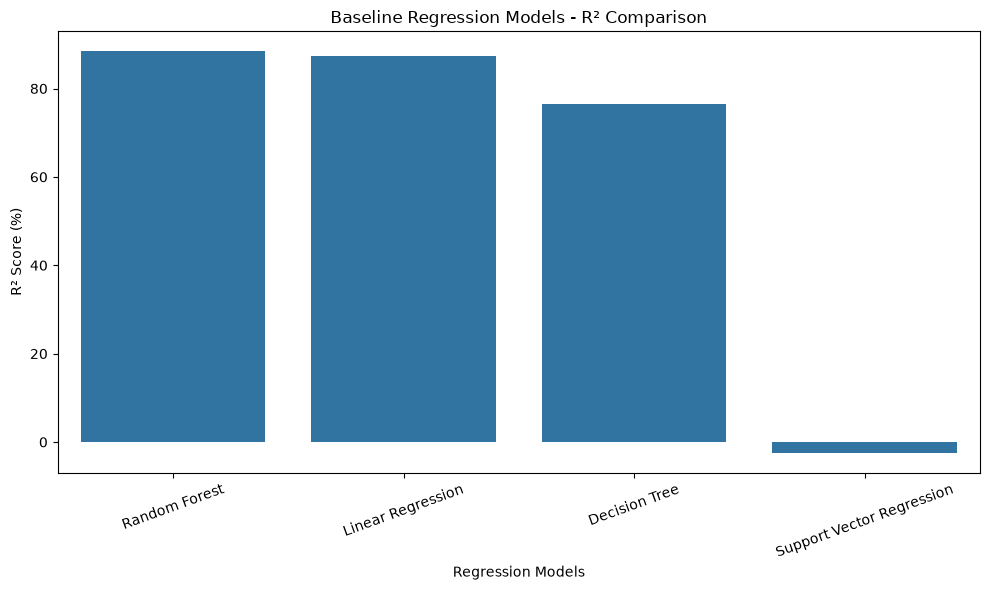

In [7]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="R² (%)"
)

plt.title("Baseline Regression Models - R² Comparison")
plt.xlabel("Regression Models")
plt.ylabel("R² Score (%)")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

##### **Section 8 – Prediction Error Comparison**

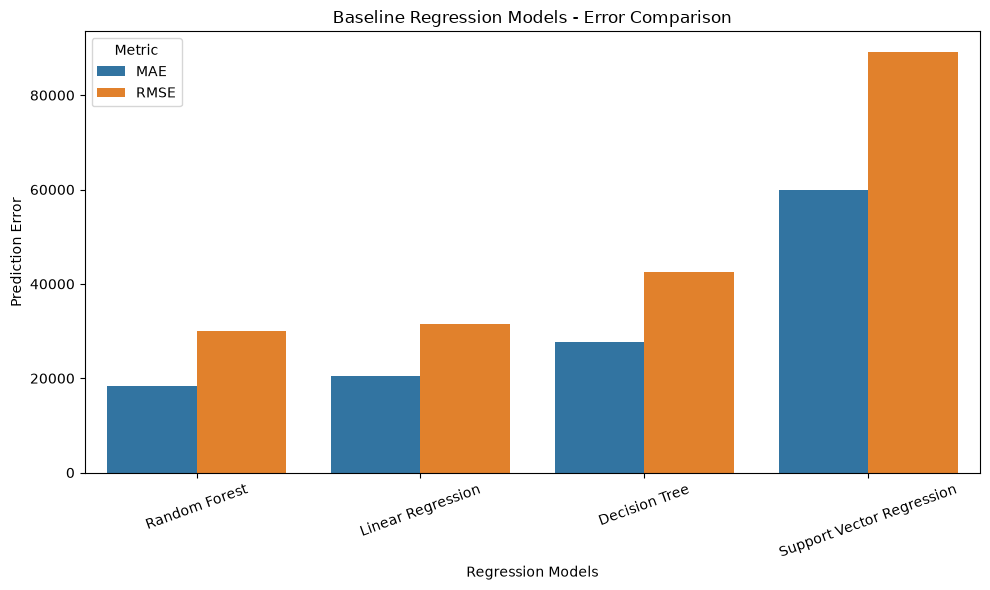

In [8]:
# Compare MAE and RMSE
metrics_comparison = comparison_df.melt(
    id_vars="Model",
    value_vars=["MAE", "RMSE"],
    var_name="Metric",
    value_name="Error"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=metrics_comparison,
    x="Model",
    y="Error",
    hue="Metric"
)

plt.title("Baseline Regression Models - Error Comparison")
plt.xlabel("Regression Models")
plt.ylabel("Prediction Error")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

##### **Section 9 – Best Baseline Model Selection**

In [9]:
# Select the top 2 models based on R²
best_two_models = comparison_df.head(2)

print("Top 2 Baseline Models:\n")

for index, row in best_two_models.iterrows():
    print(f"Model {index + 1}: {row['Model']}")
    print("Test R²:", round(row["R² (%)"], 1), "%")
    print()

Top 2 Baseline Models:

Model 1: Random Forest
Test R²: 88.4 %

Model 2: Linear Regression
Test R²: 87.3 %

